# Box Plot (Box-and-Whisker)

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Summarises a distribution with five numbers: the median, the quartiles (box) and the whiskers to 1.5×IQR, with outliers drawn as points. It is compact enough to compare many groups side by side.

## When to use

- Compare the medians and spreads of many groups
- Flag outliers
- Fit a statistical audience and small spaces

## Avoid when

- The distribution is multimodal (the box hides the peaks; use a violin or raincloud)
- Sample sizes are small (show the points instead)
- The audience is unfamiliar with quartiles

## Alternatives

- Violin plot
- Raincloud plot
- Strip plot

## Design tips

- Overlay the raw points when n is moderate
- Sort the groups by median

## Example

Days taken to pay an invoice, by customer segment, for 1,000 invoices (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(6)
segments = {"Card on file": (1.0, 0.5), "Small business": (2.9, 0.35), "Retail chain": (3.3, 0.3),
            "Enterprise": (3.6, 0.35), "Distributor": (3.5, 0.5), "Government": (3.9, 0.55)}
df = pd.concat([pd.DataFrame({"segment": d, "days_to_pay": rng.lognormal(mu, sd, 170)})
                for d, (mu, sd) in segments.items()], ignore_index=True)
order = df.groupby("segment")["days_to_pay"].median().sort_values().index.tolist()
df.groupby("segment")["days_to_pay"].median().round(1)

segment
Card on file       2.9
Distributor       35.2
Enterprise        36.7
Government        51.0
Retail chain      26.5
Small business    18.7
Name: days_to_pay, dtype: float64

### Plot

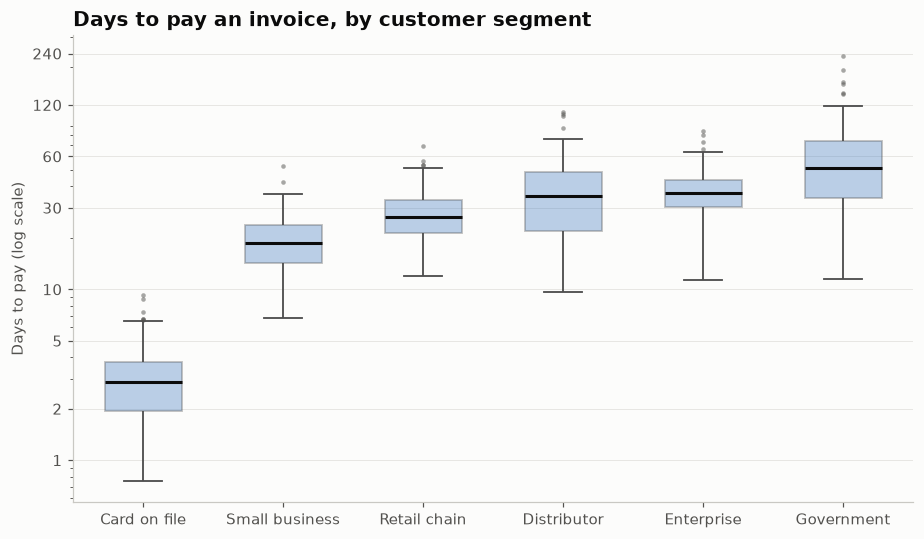

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.boxplot(data=df, x="segment", y="days_to_pay", order=order, color=PALETTE[0], width=0.55,
            boxprops=dict(alpha=0.35), linewidth=1.2,
            flierprops=dict(marker="o", markersize=3, markerfacecolor="#52514e",
                            markeredgecolor="none", alpha=0.5),
            medianprops=dict(color="#0b0b0b", linewidth=2), ax=ax)
ax.set_yscale("log")
ax.set_yticks([1, 2, 5, 10, 30, 60, 120, 240], ["1", "2", "5", "10", "30", "60", "120", "240"])
ax.set_xlabel(None)
ax.set_ylabel("Days to pay (log scale)")
ax.set_title("Days to pay an invoice, by customer segment")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

The thick line is the median and the box holds the middle 50% of invoices. Whiskers reach the typical range and dots are outliers. Government customers pay slowest and least predictably, which matters for cash-flow planning.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.box(df, x="segment", y="days_to_pay", points="outliers", log_y=True,
             category_orders={"segment": order}, color_discrete_sequence=PALETTE,
             labels={"segment": "", "days_to_pay": "Days to pay (log scale)"},
             title="Days to pay an invoice, by customer segment")
fig.show()   # hover a box for median, quartiles and fences

---
Standalone script: [`box_plot.py`](box_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)